In [2]:
#pip install torch torchvision opencv-python

#TODO
#Split training data into 90-10 train, val(small validation set should speed up training)
#Implement Freezing early weights
#Do proper eval

In [129]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
from os.path import isfile, isdir
from os import makedirs
#from torchvision.models.mobilenetv2 import mobilenet_v2
from torchvision.models.mobilenetv3 import mobilenet_v3_large
mobilenet_V2 = mobilenet_v3_large

from datetime import datetime           #File timstamp
import time                             #T+121239
from PIL import Image                   #Needed to load random image
import cv2 as cv                        #Show images and stuff(Can also be done with PIL
import matplotlib.pyplot as plt         #Show images for colab
import numpy as np                      #Honestly this should just be a core library

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)
Timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

cuda:0


In [130]:
class LeNet(nn.Module):
    def __init__(self, output_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=12, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=12, out_channels=24, kernel_size=5)
        self.fc_1 = nn.Linear(24 * 29 * 29, 120)
        self.fc_2 = nn.Linear(120, 84)
        self.fc_3 = nn.Linear(84, output_dim)

    def forward(self, x):
        x = self.conv1(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = F.relu(x)
        x = x.view(x.shape[0], -1)
        x = self.fc_1(x)
        x = F.relu(x)
        x = self.fc_2(x)
        x = F.relu(x)
        x = self.fc_3(x)
        return x

In [131]:
#Pretrained model weight None>Random, "DEFAULT">torch MobileNetV2, "IMAGENET1K_V1">original MobileNetV2, or "FILENAME" for custom
PTWeights = "DEFAULT"
PTFreeze = False                             #Freeze Non-Output layer
PTOutputs = 5                             #Alter Output size if different from loaded network (WILL wipe weights for this)
TrainingRate = 0.01
TrainingEpochs = 100
EarlyStop = 10

PreProcess = v2.Compose([                   #Preprocessing steps to get dataset to appropriate format
    v2.Resize(224),                         #Resizes to 224px short side
    v2.Resize(None, max_size=224),          #Resizes to 224px long side
    v2.Pad(100),
    v2.CenterCrop(224),                     #Crops excess on long side
    v2.ToImage(),                           #Makes it an image???
    v2.ToDtype(torch.float32, scale = True), #Changes datatype to float and value range from 0-255 to 0-1
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),    #Normalizes image because apparently the (pretrained)model likes that
])
#model = mobilenet_v2(weights=None)          #This model wants data in the format of Color, Y, X and i hate it
model = mobilenet_v2(weights="DEFAULT")          #This model wants data in the format of Color, Y, X and i hate it

#PreProcess = v2.Compose([                   #Preprocessing steps to get dataset to appropriate format
    #v2.Grayscale(1),
    #v2.Resize(224),                         #Resizes to Xpx short side
    #v2.Resize(None, max_size=128),          #Resizes to Xpx long side
    #v2.Pad(50),
    #v2.CenterCrop(128),                     #Crops excess on long side
    #v2.ToImage(),                           #Makes it an image???
    #v2.ToDtype(torch.float32, scale = True), #Changes datatype to float and value range from 0-255 to 0-1
    #v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),    #Normalizes image because apparently the (pretrained)model likes that
#])

#model = LeNet(PTOutputs)
if PTWeights and isfile(PTWeights): model.load_state_dict(torch.load(PTWeights, weights_only=True))
#if PTOutputs != model.classifier[1].out_features: model.classifier[1] = nn.Linear(model.classifier[1].in_features, PTOutputs)
if PTFreeze:
    for param in model.parameters():
        param.requires_grad = False
    model.classifier[-1].weight.requires_grad = True
    model.classifier[-1].bias.requires_grad = True

In [132]:
AnnotationLevel = "family"
AnnotationFile = "./fgvc-aircraft-2013b/data/families.txt"

In [133]:
import json

import os, fnmatch
def find(pattern, path):
    result = []
    for root, dirs, files in os.walk(path):
        for name in files:
            if fnmatch.fnmatch(name, pattern):
                result.append(os.path.join(root, name))
    return result



In [134]:
######Custom data loading
from os import listdir

Folder = "../OURdata/SingleSignDataCopy/im/"
LabelsDic = {
    'dirty': 0,
    'damaged': 1,
    'vandalized': 2,
    'faded': 3,
    'obscured': 4,
    'undamaged': 5
}

class OURdata(Dataset):
    def __init__(self, root_dir, transform=None):
        """
        Arguments:
            csv_file (string): Path to the csv file with annotations.
            root_dir (string): Directory with all the images.
            transform (callable, optional): Optional transform to be applied
                on a sample.
        """
        self.data = []
        self.labels = []
        self.transform = v2.Compose([v2.PILToTensor()])

        with open(Folder+'../jsonOne.json', 'r',encoding="utf-8") as f:
            allJJJ = json.load(f)
        for jasonOne in allJJJ:
            imName = jasonOne['file_upload'].split('-')[-1]
            labels = [0]*6
            results = jasonOne['annotations'][0]['result']
            for result in results:
                choices = result['value']['choices']
                for choice in choices:
                    labels[LabelsDic[choice]] = 1
            im = Image.open(Folder + imName).convert('RGB')
            self.data.append(im)
            self.labels.append(torch.Tensor(labels))
        
        self.root_dir = root_dir
        if transform != None: self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        sample = self.data[idx]
        label = self.labels[idx]
        
        if self.transform:
            sample = self.transform(sample)

        return sample, label
FullData = OURdata(Folder, PreProcess)
#TrainData, TestData = torch.utils.data.random_split(FullData, [0.8, 0.2])
TrainData = FullData
TestData = FullData

torch.Size([3, 224, 224])
tensor([0., 0., 1., 0., 0., 0.])


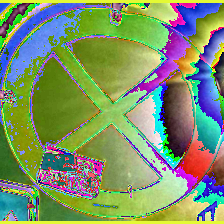

In [135]:
print(FullData[0][0].shape)
print(FullData[0][1])
display(v2.ToPILImage()(FullData[0][0]))

In [136]:
#TrainData = datasets.FGVCAircraft(root="./", split="train", annotation_level=AnnotationLevel, download=True, transform=PreProcess)
#TestData = datasets.FGVCAircraft(root="./", split="test", annotation_level=AnnotationLevel, download=True, transform=PreProcess)
TrainDataLoader = torch.utils.data.DataLoader(TrainData, batch_size=80, shuffle=True, pin_memory=True)#, num_workers=args.nThreads
TestDataLoader = torch.utils.data.DataLoader(TestData, batch_size=80, shuffle=True, pin_memory=True)#, num_workers=args.nThreads

In [137]:
#criterion = nn.BCEWithLogitsLoss()
criterion = nn.CrossEntropyLoss()       #Multiclass classification
optimizer = torch.optim.Adam(model.parameters(), lr=TrainingRate)
def TrainEpoch():                       #Trains once on all training data
    accumulatedLoss = 0.0
    #Train on the whole dataset but tragically my GPU doesnt fit the whole dataset
    #(which is weird because its only a few GB) so it has to be in batches
    for BatchID, Batch in enumerate(TrainDataLoader):
        BatchIm, BatchLabel = Batch
        BatchIm, BatchLabel = BatchIm.to(device), BatchLabel.to(device)     #Put stuff on GPU(if cuda is available)

        optimizer.zero_grad()                   #Reset gradients
        output = model(BatchIm)[:,:6]                 #Make predictions
        loss = criterion(output, BatchLabel)    #How wrong are we
        loss.backward()                         #Change model weights based on how wrong we are
        optimizer.step()
        accumulatedLoss += loss.item()
    return accumulatedLoss / TrainDataLoader.batch_size

In [138]:
def TrainEpochs(Epochs):
    
    if not isdir(f"./{model.__class__.__name__}/"): makedirs(f"./{model.__class__.__name__}/")
    model.to(device)
    BestTest = np.inf
    NoImprovement = 0
    tStart = time.time()
    for Epoch in range(Epochs):
        model.train(True)
        print(f"Train T+{time.time() - tStart:>5.0f}")
        LossTrain = TrainEpoch()
    
        LossTest = 0.0
        model.eval()
        with torch.no_grad():
            print(f"Eval  T+{time.time() - tStart:>5.0f}")
            for BatchID, Batch in enumerate(TestDataLoader):
                BatchIm, BatchLabel = Batch
                
                BatchIm, BatchLabel = BatchIm.to(device), BatchLabel.to(device)     #Put stuff on GPU(if cuda is available)
                output = model(BatchIm)[:,:6]                                           #Make predictions
                LossTest += criterion(output, BatchLabel)                           #How wrong are we
    
            LossTest = LossTest / TestDataLoader.batch_size
    
        if LossTest < BestTest:
            BestTest, NoImprovement = LossTest, 0
            torch.save(model.state_dict(), f"./{model.__class__.__name__}/{Timestamp}_best")
        else:
            NoImprovement += 1
            if NoImprovement > EarlyStop:
                print(f"Training does not continue until morale improves")
                torch.save(model.state_dict(), f"./{model.__class__.__name__}/{Timestamp}_final")
                break
        print(f"Epoch [{Epoch+1:>3}/{Epochs:>3}] T+{time.time() - tStart:>5.0f}, Training Loss: {LossTrain:>6.3f}, Test Loss: {LossTest:>6.3f},  Worse then best [{NoImprovement:>2}/{EarlyStop:>2}]")

In [139]:
TrainEpochs(TrainingEpochs)

Train T+    0
Eval  T+    2
Epoch [  1/100] T+    2, Training Loss:  0.023, Test Loss:  0.144,  Worse then best [ 0/10]
Train T+    2
Eval  T+    3
Epoch [  2/100] T+    4, Training Loss:  0.011, Test Loss:  0.315,  Worse then best [ 1/10]
Train T+    4
Eval  T+    5
Epoch [  3/100] T+    5, Training Loss:  0.013, Test Loss:  0.173,  Worse then best [ 2/10]
Train T+    5
Eval  T+    6
Epoch [  4/100] T+    7, Training Loss:  0.035, Test Loss:  0.256,  Worse then best [ 3/10]
Train T+    7
Eval  T+    8
Epoch [  5/100] T+    8, Training Loss:  0.006, Test Loss:  0.117,  Worse then best [ 0/10]
Train T+    8
Eval  T+   10
Epoch [  6/100] T+   10, Training Loss:  0.003, Test Loss:  0.095,  Worse then best [ 0/10]
Train T+   10
Eval  T+   11
Epoch [  7/100] T+   12, Training Loss:  0.002, Test Loss:  0.107,  Worse then best [ 1/10]
Train T+   12
Eval  T+   13
Epoch [  8/100] T+   13, Training Loss:  0.001, Test Loss:  0.129,  Worse then best [ 2/10]
Train T+   13
Eval  T+   14
Epoch [  9/1

In [144]:
numberID = 1
testImage, Label = TestData[numberID]
print(f"It is a ({Label}){Label}", testImage.shape)
testTensor = PreProcess(testImage).unsqueeze(0).to(device)  #Put the image through the preprocessing, then unsqueeze to add an extra dimension(image is 3D this model wants 4D
#display(TestData[numberID][0].to_pil_image())
#display(testImage)

result = model(testTensor)[:,:6]
probabilities = F.softmax(result, dim=1).squeeze()
topProb, topClass = torch.topk(probabilities, 6)
for i in range(len(topProb)):
    print(f"I am {topProb[i].item():.2f} percent sure this is a {"annotations[topClass[i].item()]"} Class:{topClass[i].item()}")

It is a (tensor([0., 0., 0., 0., 1., 0.]))tensor([0., 0., 0., 0., 1., 0.]) torch.Size([3, 224, 224])
I am 0.70 percent sure this is a annotations[topClass[i].item()] Class:0
I am 0.30 percent sure this is a annotations[topClass[i].item()] Class:5
I am 0.00 percent sure this is a annotations[topClass[i].item()] Class:2
I am 0.00 percent sure this is a annotations[topClass[i].item()] Class:4
I am 0.00 percent sure this is a annotations[topClass[i].item()] Class:3
I am 0.00 percent sure this is a annotations[topClass[i].item()] Class:1


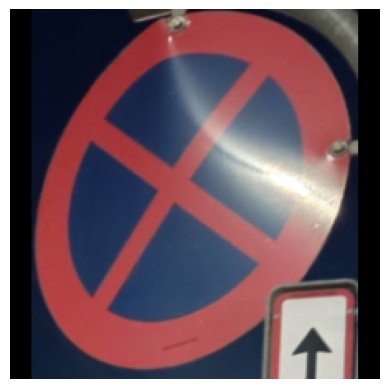

In [145]:
mean = torch.tensor([0.485, 0.456, 0.406])
std  = torch.tensor([0.229, 0.224, 0.225])

img = testImage.cpu().detach()

# Undo normalization
img = img * std[:, None, None] + mean[:, None, None]

# Convert C, H, W -> H, W, C for matplotlib
img = img.permute(1, 2, 0).clamp(0, 1)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
#from google.colab.patches import cv2_imshow
#testImage, Label = TestData[numberID]
#testImage = testImage.permute(1, 2, 0).numpy() * 200
#cv2_imshow(testImage)
#print(Label)

In [ ]:
def count_parameters(model):
    print(f"{"Layer name":^30}|{"Parameters":>10}|{"Trainable":>10}")
    total_params, train_params = 0, 0
    for name, parameter in model.named_parameters():
        #if not parameter.requires_grad: continue
        params = parameter.numel()
        print(f"{name:<30}|{params:>10}|{params*parameter.requires_grad:>10}")
        total_params += params
        if parameter.requires_grad: train_params += params
    print(f"{"Total parameters":<30}|{total_params:>10}|{train_params:>10}")
count_parameters(model)

Some things i learned:
freezing all parameters except classifier layer reduces GPU usage during training a *lot*, so we might be able to train a model on UCloud decently fast if we just fine tune? It does not actually train faster on my computer but thats because CPU is the limit for me

possibly because of backpropagation not needing to calculate so many gradients, possibly due to just not tracking gradients
fully trimmed model i tested also replaced classifier layer with one that only had 100 outputs instead of 1000
since MobileNetV2 is trained on a dataset with 1000 classes and we only have a bit under 100

this means it only trains 128100 parameters instead of 3504872, and is what is called "fine tuning"(i think) since you leave almost the whole model intact and just retrain the output layers

the fully trimmed down model used only about 2GB VRAM and barely any work on GPU

In [ ]:
print(model)

LeNet(
  (conv1): Conv2d(3, 9, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(9, 27, kernel_size=(5, 5), stride=(1, 1))
  (fc_1): Linear(in_features=432, out_features=120, bias=True)
  (fc_2): Linear(in_features=120, out_features=84, bias=True)
  (fc_3): Linear(in_features=84, out_features=7, bias=True)
)
